# Домашнее задание 2

В этом задании вам предстоит реализовать контрастивное обучние эмбеддера, посмотреть на его влияние на задаче классификации и отбора кандидатов.

Языковое моделирование рассматривать не будем в силу дороговизны подхода.

## Часть 1. Triplet loss на стероидах

Вам поставили задачу: на фиксированном множестве точек произвести классификацию, при этом множество таково, что качество на исходных данных неприемлемо. Что делать? Последуем совету из лекции и реализуем контрастивное обучение.

В этом и последующем задании вам предстоит реализовать дообучение некоторого простого эмбеддера на домен.

Эмбеддинги заморожены -- будем дообучать только полносвязную голову.

In [3]:
from dataclasses import dataclass

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
SEED = 42

@dataclass
class DatasetConfig:
    n_samples: int = 5000
    n_features: int = 32
    n_classes: int = 8
    n_clusters_per_class: int = 2
    n_informative: int = 5
    random_state: int = SEED

@dataclass
class SplitConfig:
    random_state: int = SEED
    test_size: float = 0.25

In [5]:
X, y = make_classification(**DatasetConfig().__dict__)

X_train, X_test, y_train, y_test = train_test_split(X, y, **SplitConfig().__dict__)
X_train, y_train = torch.from_numpy(X_train).float(), torch.from_numpy(y_train).float()

## 1.Визуализация данных - 1 баллов

Напишите функцию `plot_tsne(data, labels, **kwargs)`, принимающую на вход матрицу эмбеддингов и метки классификации и строящую t-SNE-разложение на плоскости. Изобразите его, раскрасив классы по цветам. Зафиксируйте `random_state` при построении.

Цель задания: получить визуальное представление о природе распределения в данных. Для доменной адаптации визуализация - важный инструмент интерпретации результата.

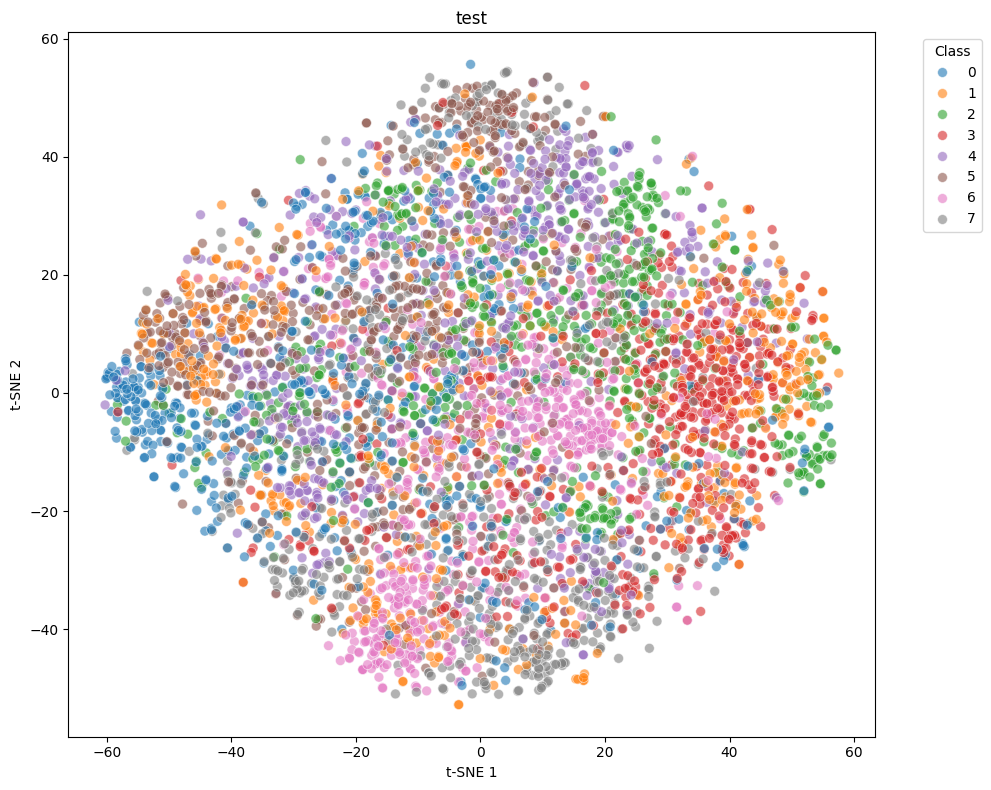

In [6]:

# ---- Ваш код здесь ----
def plot_tsne(data, labels, plot_title):
    # Преобразование данных в numpy, если это torch tensor
    if isinstance(data, torch.Tensor):
        data = data.numpy()
    if isinstance(labels, torch.Tensor):
        labels = labels.numpy()
    
    # Построение t-SNE
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter_without_progress=1000)
    data_2d = tsne.fit_transform(data)
    
    # Создание DataFrame для удобной визуализации
    df = pd.DataFrame({
        'x': data_2d[:, 0],
        'y': data_2d[:, 1],
        'class': labels.astype(int)
    })
    
    # Построение графика
    plt.figure(figsize=(10, 8))
    sns.scatterplot(
        data=df, 
        x='x', 
        y='y', 
        hue='class',
        palette='tab10',
        alpha=0.6,
        s=50
    )
    plt.title(plot_title)
    plt.xlabel('t-SNE 1')
    plt.ylabel('t-SNE 2')
    plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
plot_tsne(X, y, "test")
# ---- Конец кода ----


## 2.Базовый классификатор

Выберем алгоритм классификации kNN и метрику качества Accuracy. Оценим базовое качество на тестовых данных.

In [7]:


clf = KNeighborsClassifier(n_neighbors=10)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
score = accuracy_score(y_test, y_pred)

print(score)

0.5144


## 3.TripletLoss - 5 баллов

Давайте разберёмся, что такое Triplet Loss и как мы будем его использовать в несколько изменённом виде.

### Идея Triplet Loss

Цель обучения на Triplet Loss — научить модель отличать похожие объекты от непохожих. Для этого мы работаем с "триплетами" (тройками) векторов:

1.  **Якорь (`anchor`)**: Вектор нашего основного объекта $x$.
2.  **Позитив (`positive`)**: Вектор объекта $x^+$, который относится к тому же классу, что и якорь.
3.  **Негатив (`negative`)**: Вектор объекта $x^-$ из другого класса.

Цель — сделать так, чтобы в пространстве векторов "якорь" был ближе к "позитиву", чем к "негативу", причём с некоторым запасом (`margin`).

Функция ошибки Triplet Loss для одного триплета выглядит так:

$$\max\left(0,\|f(x)-f(x^+)\|^2_2-\|f(x)-f(x^-)\|^2_2+\varepsilon\right)$$

Заметим, что в случае L2-нормилизованных векторов:

$$\max\left(0,\|f(x)-f(x^+)\|^2_2-\|f(x)-f(x^-)\|^2_2+\varepsilon\right)=\max\left(0,f(x)f^T(x^-)-f(x)f^T(x^+)+\hat{\varepsilon}\right)$$

Пусть $D=\{x_i, y_i\}_i$ -- выборка классификации. Позитивные пары в $D$ формируются такими $(i,j)$, что $i \neq j$ и $y_i = y_j$, негативные - $i \neq j$ и $y_i \neq y_j$. Пусть $S=XX^T - \text{diag}(XX^T)$, где $\text{diag}(А)$ - преобразование квадратной матрицы $A$ к диагональной, в которой элементы на диагонали совпадают с диагональю $A$. То есть в $S$ диагональ занулена. По матрице $S$ можно сформировать два непересекающихся множества: позитивов $P$ и негативов $N$. Пусть $L$ -- минимальное количество элементов в каждом из двух множеств. Возьмем $\hat{P}=\{p_i\}_i$, $\hat{N}=\{n_i\}_i$ как сэмплы без возвращения размера $L$ из $P$ и $N$ соответственно. Тогда итоговая функция ошибки выглядит так:

$$\mathcal{L}=\frac{1}{L}\sum\limits_{i=1}^L\max\left(0, n_i-p_i+\hat{\varepsilon}\right)$$

В чем модификация? В том, что в паре позитивов и негативов не обязательно должен быть один и тот же якорный элемент. И это работает.

Реализуйте callable-класс `TripletLoss` по описанию.

Примечание: для прохождения тестов используйте сэмплирование через `np.random.default_rng(self.random_state).choice`.

In [8]:
# ---- Ваш код здесь ----
class TripletLoss():
    
    def __init__(self, margin, random_state=None):
        self.margin = margin
        self.random_state = random_state

    def __call__(self, x, labels):
        device = x.device
        dtype = x.dtype
        
        # L2-нормализация
        x_norm = torch.norm(x, p=2, dim=1, keepdim=True)
        x_normalized = x / (x_norm + 1e-8)
        
        # Матрица сходства
        S = x_normalized @ x_normalized.T
        
        # Зануляем диагональ
        n_samples = x.shape[0]
        mask_diag = torch.eye(n_samples, device=device, dtype=dtype)
        S = S * (1 - mask_diag)
        
        # Формируем маски позитивов и негативов
        labels_flat = labels.view(-1)
        labels_equal = (labels_flat.view(-1, 1) == labels_flat.view(1, -1)).float()
        mask_no_diag = 1 - torch.eye(n_samples, device=device, dtype=dtype)
        
        positive_mask = labels_equal * mask_no_diag
        negative_mask = (1 - labels_equal) * mask_no_diag
        
        # Собираем значения позитивов и негативов
        positive_pairs = S[positive_mask > 0]
        negative_pairs = S[negative_mask > 0]
        
        # Сэмплирование индексов через numpy для детерминизма
        if len(positive_pairs) == 0 or len(negative_pairs) == 0:
            return torch.tensor(0.0, dtype=dtype, device=device, requires_grad=True)
        
        L = min(len(positive_pairs), len(negative_pairs))
        
        # Сэмплируем ИНДЕКСЫ (не значения) через numpy
        rng = np.random.default_rng(self.random_state)
        if L < len(positive_pairs):
            pos_indices = rng.choice(len(positive_pairs), size=L, replace=False)
        else:
            pos_indices = np.arange(len(positive_pairs))
            
        if L < len(negative_pairs):
            neg_indices = rng.choice(len(negative_pairs), size=L, replace=False)
        else:
            neg_indices = np.arange(len(negative_pairs))
        
        # Берем значения по индексам через PyTorch
        positive_sampled = positive_pairs[torch.tensor(pos_indices, device=device)]
        negative_sampled = negative_pairs[torch.tensor(neg_indices, device=device)]
        
        # Расчет loss через PyTorch операции (сохраняем градиенты)
        triplet_loss = torch.clamp(negative_sampled - positive_sampled + self.margin, min=0.0)
        loss = triplet_loss.mean()
        
        return loss

In [9]:
criterion = TripletLoss(0.2063, random_state=101)


objects = torch.tensor(
    [[-1.7651, -1.5979,  0.1042,  0.3825, -0.9419, -0.2580, -0.6087, -0.1711,
        1.3922,  0.8548, -0.9251,  0.6989,  0.4238, -0.1330,  0.2985],
    [ 1.6144,  0.0627,  0.3424, -0.8591,  0.1869, -0.8598, -0.7200,  0.9449,
        -0.1684,  1.0282, -1.2377, -1.2640,  0.7469,  1.9605, -0.1214],
    [ 1.1143, -0.6948,  0.3739, -1.1461,  0.6456, -0.3360, -0.8111, -0.8861,
        0.7176, -0.6235, -0.9364,  0.6174,  2.7212, -2.0703, -2.2571],
    [ 0.7525,  2.1028,  2.7782,  0.5040, -1.5791,  1.5342,  0.0816,  0.3245,
        -0.0857, -0.5992, -1.4339,  0.0897, -1.5096,  0.1428, -0.1488],
    [-0.7518,  0.2623, -0.4958, -1.6063,  0.2537, -0.1137,  0.3985,  1.0155,
        0.1874, -0.4300, -1.2309,  1.5760, -1.3176,  1.5355,  1.8471],
    [ 1.9290, -0.3236,  0.4303,  0.7111,  1.4234,  1.7901,  0.2216, -1.5471,
        0.9389, -0.3012, -1.6487,  1.5765, -1.1450,  0.3260,  0.4909],
    [ 0.7837, -0.8004, -0.0929, -1.2220,  2.2333,  0.3288, -0.5222, -0.7202,
        0.6147,  1.8012, -0.2388, -0.2539,  0.0191, -0.0104,  0.5717],
    [-0.2709, -1.7985, -0.3959, -1.1190,  0.8644,  0.3008, -1.0336, -0.1251,
        -0.3357,  0.7938,  3.2090, -0.4332, -0.0496, -0.2672,  0.9690],
    [-0.1109,  0.4130,  0.7406, -1.2446, -0.4252,  2.5128, -0.2765,  0.6845,
        1.1965,  1.4173, -1.4604,  0.2515,  0.6387, -1.8519,  1.1899],
    [-0.1781, -0.7473, -0.1015,  0.2280, -1.5815,  0.1535, -1.3912, -2.2026,
        1.0496,  0.3547,  0.8897, -0.6482,  0.0133,  1.0124, -0.4452]])

labels = torch.LongTensor([1, 1, 2, 2, 3, 3, 4, 4, 5, 5])
print(criterion(objects, labels)- 0.29527)


assert (abs(criterion(objects, labels).item() - 0.29527) < 1e-4)

tensor(-8.0705e-05)


## 4.Модель и функция обучения - 8 балла

Реализуйте функцию `domain_adaptation(X_train, y_train, hidden_dim, out_dim, margin, N_epoch, batches_per_epoch, batch_size) -> MLP`, базовый цикл batch-обучения линейной головы, полносвязной нейронной сети. Батч для обучения можно либо сэмплировать произвольно из всего обучающего множества через `random.choice`, либо заранее сделать случайную перестановку датасета, как итог пройти `batches_per_epoch` батчей из датасета за одну эпоху.

Используйте реализацию полносвязной нейронной сети через класс `MLP`.

Требуется выбить на тесте 0.60 точности.

Цель задания - закрепить использование `TripletLoss` на простых модельных данных.

In [10]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, out_dim, drop_prob=0.2):
        super().__init__()

        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, out_dim)
        self.bn = nn.BatchNorm1d(hidden_dim)
        self.drop = nn.Dropout(drop_prob)
        self.act = nn.GELU()

    def forward(self, x):
        x = self.drop(x)
        x = self.fc1(x)
        x = self.bn(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        return x

In [11]:
# ---- Ваш код здесь ----
def domain_adaptation(
        X_train, y_train,
        hidden_dim=128, out_dim=64, margin=0.2,
        N_epoch=40, batches_per_epoch=750, batch_size=72,
        device=None):

    # Определяем устройство
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    elif isinstance(device, str):
        device = torch.device(device)
    
    print(f"Using device: {device}")
    
    # Устанавливаем seed для воспроизводимости
    torch.manual_seed(42)
    np.random.seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(42)
    
    input_dim = X_train.shape[1]
    model = MLP(input_dim=input_dim, hidden_dim=hidden_dim, out_dim=out_dim).to(device)
    
    X_train_device = X_train.to(device)
    y_train_device = y_train.to(device)
    
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)
    

    criterion = TripletLoss(margin=margin, random_state=42)
    
    model.train()
    n_samples = X_train_device.shape[0]
    
    for epoch in range(N_epoch):
        # Создаем перестановку для смешивания данных
        perm = torch.randperm(n_samples, device=device)
        X_shuffled = X_train_device[perm]
        y_shuffled = y_train_device[perm]
        
        for batch_idx in range(batches_per_epoch):
            start_idx = (batch_idx * batch_size) % n_samples
            end_idx = start_idx + batch_size
            
            if end_idx > n_samples:
                X_batch = torch.cat([
                    X_shuffled[start_idx:n_samples],
                    X_shuffled[0:(end_idx - n_samples)]
                ], dim=0)
                y_batch = torch.cat([
                    y_shuffled[start_idx:n_samples],
                    y_shuffled[0:(end_idx - n_samples)]
                ], dim=0)
            else:
                X_batch = X_shuffled[start_idx:end_idx]
                y_batch = y_shuffled[start_idx:end_idx]

            optimizer.zero_grad()
            embeddings = model(X_batch)
            

            loss = criterion(embeddings, y_batch)
            loss.backward()
            optimizer.step()
        
        print(f"Epoch {epoch+1}/{N_epoch}, Loss: {loss.item():.4f}")
    
    return model

model = domain_adaptation(X_train, y_train, N_epoch=40, batches_per_epoch=750, batch_size=72)
# ---- Конец кода ----


Using device: cuda
Epoch 1/40, Loss: 0.1739
Epoch 2/40, Loss: 0.1504
Epoch 3/40, Loss: 0.1982
Epoch 4/40, Loss: 0.1616
Epoch 5/40, Loss: 0.1786
Epoch 6/40, Loss: 0.1719
Epoch 7/40, Loss: 0.2008
Epoch 8/40, Loss: 0.1751
Epoch 9/40, Loss: 0.1740
Epoch 10/40, Loss: 0.1267
Epoch 11/40, Loss: 0.1716
Epoch 12/40, Loss: 0.1739
Epoch 13/40, Loss: 0.1841
Epoch 14/40, Loss: 0.1842
Epoch 15/40, Loss: 0.1737
Epoch 16/40, Loss: 0.1687
Epoch 17/40, Loss: 0.1419
Epoch 18/40, Loss: 0.1779
Epoch 19/40, Loss: 0.1541
Epoch 20/40, Loss: 0.1482
Epoch 21/40, Loss: 0.1643
Epoch 22/40, Loss: 0.1721
Epoch 23/40, Loss: 0.1564
Epoch 24/40, Loss: 0.1623
Epoch 25/40, Loss: 0.1884
Epoch 26/40, Loss: 0.1690
Epoch 27/40, Loss: 0.1640
Epoch 28/40, Loss: 0.1692
Epoch 29/40, Loss: 0.1975
Epoch 30/40, Loss: 0.1684
Epoch 31/40, Loss: 0.1542
Epoch 32/40, Loss: 0.1479
Epoch 33/40, Loss: 0.1662
Epoch 34/40, Loss: 0.1702
Epoch 35/40, Loss: 0.1656
Epoch 36/40, Loss: 0.1621
Epoch 37/40, Loss: 0.1391
Epoch 38/40, Loss: 0.1844
Ep

In [16]:

model.eval()
if isinstance(X_test, np.ndarray):
    X_test_tensor = torch.from_numpy(X_test).float()
else:
    X_test_tensor = X_test


with torch.no_grad():
    X_test_transformed = model(X_test_tensor.to('cuda'))

X_test_transformed_np = X_test_transformed.detach().cpu().numpy()


from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

clf = KNeighborsClassifier(n_neighbors=10)
clf.fit(X_test_transformed_np, y_test)

y_pred = clf.predict(X_test_transformed_np)

Accuracy после доменной адаптации: 0.607


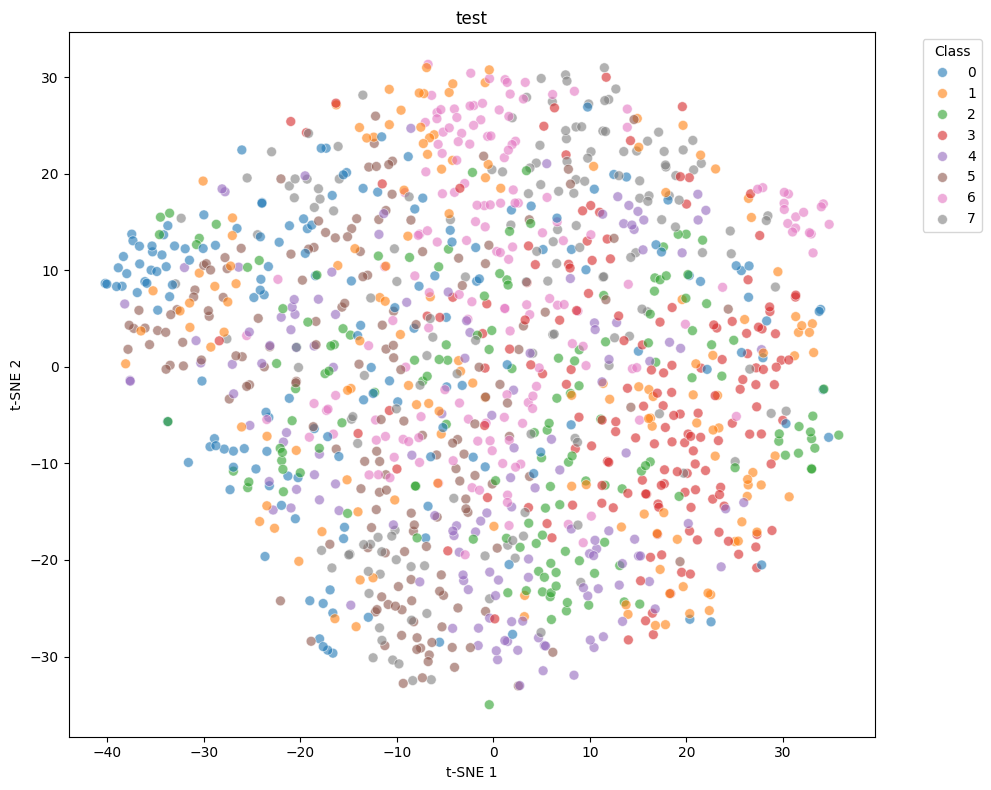

In [13]:
plot_tsne(X_test, y_test, "test")

## 5.Итоговое качество - 1 балл

Отобразите новое распределение t-SNE-координат и посчитайте тестовую метрику. Сделайте краткий вывод.

Что тут важно: перед тем, как применить kNN-классификатор, который несколько строчек кода назад был нашим baseline-решением, нужно применить над исходными данными преобразование обученной моделью представлений, фактически выходом функции `domain_adaptation`.

Цель задания: изучить, как поменялось распределение в данных после доменной адаптации.

Визуализируем успех


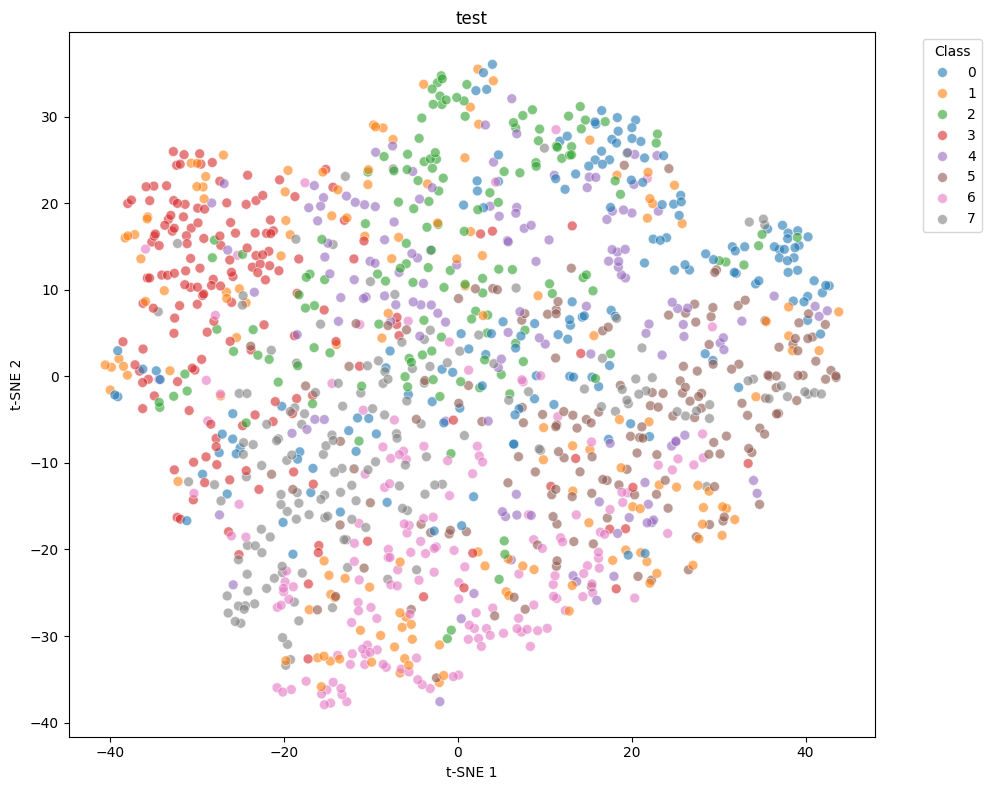

In [17]:
# ---- Ваш код здесь ----
print("Визуализируем успех")
# ---- Конец кода ----
plot_tsne(X_test_transformed.detach().cpu(), y_test, "test")

In [18]:
# ---- Ваш код здесь ----
print("Считаем точность на тесте")
# ---- Конец кода ----
score = accuracy_score(y_test, y_pred)
print(f"Accuracy после доменной адаптации: {score:.3f}")

Считаем точность на тесте
Accuracy после доменной адаптации: 0.607


## Часть 2. Triplet loss на чем-то посерьезнее

Рассмотрим теперь более живую задачу классификации. Будем работать с новостными группами.

Постановка та же, только возьмем теперь предобученный эмбеддер с HF. Эмбеддинги заморожены -- будем дообучать только полносвязную голову.

Поменяем так же алгоритм классификации с kNN на LogReg (по большей части для разнообразия).

In [19]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [20]:
categories = [
    "sci.space",
    "sci.med",
    "sci.electronics",
    "comp.os.ms-windows.misc",
    "comp.sys.ibm.pc.hardware",
    "comp.sys.mac.hardware"
]

newsgroups_train = fetch_20newsgroups(subset="train", categories=categories)
newsgroups_test = fetch_20newsgroups(subset="test", categories=categories)

X_train = newsgroups_train.data
X_test = newsgroups_test.data

y_train = newsgroups_train.target
y_test = newsgroups_test.target

In [21]:
def test_logreg(X_train_mapped, y_train, X_test_mapped, y_test, target_names=newsgroups_test.target_names):
    clf = LogisticRegression(max_iter=10000)
    clf.fit(X_train_mapped, y_train)

    y_pred = clf.predict(X_test_mapped)
    score = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, target_names=target_names)

    print(f"Accuracy: {score:.3f}")
    print(f"Classification Report: {report}")

## 1.Выбираем англоязычный эмбеддер и формируем эмбеддинги - 1 балл

Выберите небольшой англоязычный sentence-трансформер, обученный на семантику, и прогоните через нее тексты обучения и тестирования.

Замерьте базовое качество классификатора на этих эмбеддингах.

Опционально: крайне рекомендую прогнать `plot_tsne` из прошлой части на тесте в тех же целях, что и в прошлых заданиях.

Цель задания: применить навыки выбора модели на основе описания ее области применения.

In [31]:
import torch
from tqdm import tqdm
from sentence_transformers import SentenceTransformer

model_name = "sentence-transformers/all-MiniLM-L6-v2"
print(f"Загружаем модель: {model_name}")
model = SentenceTransformer(model_name)

print("Получаем эмбеддинги для обучающих данных...")
X_train_emb = model.encode(X_train, show_progress_bar=True, batch_size=32)

print("Получаем эмбеддинги для тестовых данных...")
X_test_emb = model.encode(X_test, show_progress_bar=True, batch_size=32)

clf_baseline = LogisticRegression(max_iter=10000)
clf_baseline.fit(X_train_emb, y_train)

y_pred_baseline = clf_baseline.predict(X_test_emb)
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print(f"\nBaseline Accuracy: {baseline_accuracy:.3f}")
print("\nClassification Report (Baseline):")
print(classification_report(y_test, y_pred_baseline, target_names=newsgroups_test.target_names))


Загружаем модель: sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Получаем эмбеддинги для обучающих данных...


Batches:   0%|          | 0/111 [00:00<?, ?it/s]

Получаем эмбеддинги для тестовых данных...


Batches:   0%|          | 0/74 [00:00<?, ?it/s]


Baseline Accuracy: 0.827

Classification Report (Baseline):
                          precision    recall  f1-score   support

 comp.os.ms-windows.misc       0.82      0.84      0.83       394
comp.sys.ibm.pc.hardware       0.74      0.69      0.72       392
   comp.sys.mac.hardware       0.78      0.78      0.78       385
         sci.electronics       0.76      0.76      0.76       393
                 sci.med       0.94      0.95      0.94       396
               sci.space       0.92      0.93      0.93       394

                accuracy                           0.83      2354
               macro avg       0.83      0.83      0.83      2354
            weighted avg       0.83      0.83      0.83      2354



## 2.Обучаем эмбеддинги под задачу - 1 балл

Теперь точно придется обратиться к Части 1. Необходимо взять `domain adaptation` и обучить эмбеддиги на домен. Выходом будет линейная голова, как и в прошлой части, которую мы применим как преобразование исходных данных для улучшения представления и более качественного решения конечной задачи, в данном случае классификации.

In [27]:
X_train_emb_tensor = torch.from_numpy(X_train_emb).float()
X_test_emb_tensor = torch.from_numpy(X_test_emb).float()
y_train_tensor = torch.from_numpy(y_train).float()
y_test_tensor = torch.from_numpy(y_test).float()

adapted_model = domain_adaptation(
    X_train=X_train_emb_tensor,
    y_train=y_train_tensor,
    hidden_dim=256,
    out_dim=128,
    margin=0.2,
    N_epoch=50,
    batches_per_epoch=500,
    batch_size=64,
    device="cuda" 
)

Using device: cuda
Epoch 1/50, Loss: 0.1113
Epoch 2/50, Loss: 0.0886
Epoch 3/50, Loss: 0.0812
Epoch 4/50, Loss: 0.0403
Epoch 5/50, Loss: 0.0405
Epoch 6/50, Loss: 0.0306
Epoch 7/50, Loss: 0.0337
Epoch 8/50, Loss: 0.0340
Epoch 9/50, Loss: 0.0248
Epoch 10/50, Loss: 0.0150
Epoch 11/50, Loss: 0.0360
Epoch 12/50, Loss: 0.0189
Epoch 13/50, Loss: 0.0411
Epoch 14/50, Loss: 0.0208
Epoch 15/50, Loss: 0.0221
Epoch 16/50, Loss: 0.0197
Epoch 17/50, Loss: 0.0228
Epoch 18/50, Loss: 0.0186
Epoch 19/50, Loss: 0.0205
Epoch 20/50, Loss: 0.0092
Epoch 21/50, Loss: 0.0194
Epoch 22/50, Loss: 0.0124
Epoch 23/50, Loss: 0.0145
Epoch 24/50, Loss: 0.0128
Epoch 25/50, Loss: 0.0132
Epoch 26/50, Loss: 0.0118
Epoch 27/50, Loss: 0.0191
Epoch 28/50, Loss: 0.0098
Epoch 29/50, Loss: 0.0148
Epoch 30/50, Loss: 0.0076
Epoch 31/50, Loss: 0.0134
Epoch 32/50, Loss: 0.0056
Epoch 33/50, Loss: 0.0155
Epoch 34/50, Loss: 0.0340
Epoch 35/50, Loss: 0.0153
Epoch 36/50, Loss: 0.0076
Epoch 37/50, Loss: 0.0151
Epoch 38/50, Loss: 0.0121
Ep

In [32]:
adapted_model.eval() 

with torch.no_grad():
    X_train_adapted = adapted_model(X_train_emb_tensor.to('cuda')).cpu().numpy()
    X_test_adapted = adapted_model(X_test_emb_tensor.to('cuda')).cpu().numpy()

## 3.Замеряем качество - 1 балл

Обучитите базовый классификатор на новом пространстве эмбеддингов, сравните результаты с baseline-решением, полученным через функцию `test_logreg` выше, обязательно сделайте вывод.

На всякий случай, в этом задании вам тоже нужно вызвать `test_logreg`, только с другими аргументами (новым преобразованием данных).

Опционально: вновь крайне рекомендую прогнать `plot_tsne` из прошлой части на тесте, только уже в новом пространстве.

Примечание: в референсном решении качество растет с $0.821$ до $0.879$.

In [33]:
clf_adapted = LogisticRegression(max_iter=10000)
clf_adapted.fit(X_train_adapted, y_train)

y_pred_adapted = clf_adapted.predict(X_test_adapted)
adapted_accuracy = accuracy_score(y_test, y_pred_adapted)

print(f"\nAdapted Accuracy: {adapted_accuracy:.3f}")
print("\nClassification Report (After Adaptation):")
print(classification_report(y_test, y_pred_adapted, target_names=newsgroups_test.target_names))



Adapted Accuracy: 0.848

Classification Report (After Adaptation):
                          precision    recall  f1-score   support

 comp.os.ms-windows.misc       0.86      0.84      0.85       394
comp.sys.ibm.pc.hardware       0.76      0.77      0.76       392
   comp.sys.mac.hardware       0.74      0.84      0.79       385
         sci.electronics       0.85      0.73      0.79       393
                 sci.med       0.94      0.96      0.95       396
               sci.space       0.94      0.94      0.94       394

                accuracy                           0.85      2354
               macro avg       0.85      0.85      0.85      2354
            weighted avg       0.85      0.85      0.85      2354




Baseline Accuracy:  0.827
Adapted Accuracy:   0.848
Прирост качества:    0.021 (2.08%)

Ожидаемое baseline: ~0.821
Ожидаемое после адаптации: ~0.879


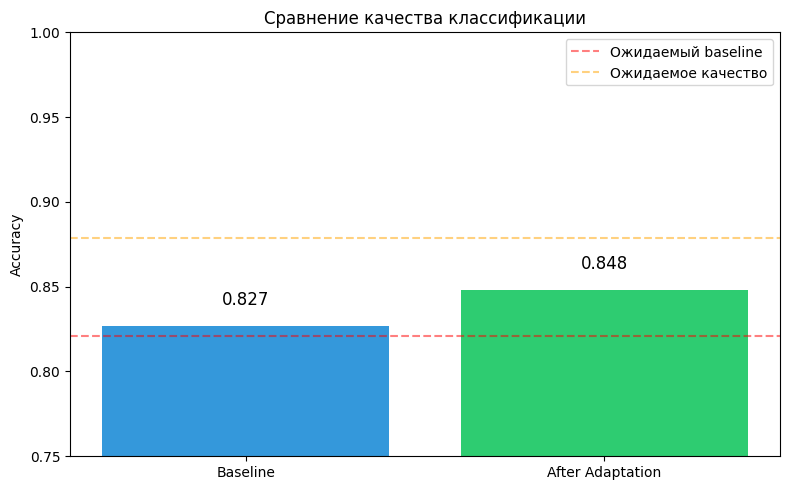

In [34]:
improvement = adapted_accuracy - baseline_accuracy
print(f"\nBaseline Accuracy:  {baseline_accuracy:.3f}")
print(f"Adapted Accuracy:   {adapted_accuracy:.3f}")
print(f"Прирост качества:    {improvement:.3f} ({improvement*100:.2f}%)")

print(f"\nОжидаемое baseline: ~0.821")
print(f"Ожидаемое после адаптации: ~0.879")


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
metrics = ['Baseline', 'After Adaptation']
accuracies = [baseline_accuracy, adapted_accuracy]

bars = plt.bar(metrics, accuracies, color=['#3498db', '#2ecc71'])
plt.ylabel('Accuracy')
plt.title('Сравнение качества классификации')
plt.ylim(0.75, 1.0)

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{acc:.3f}', ha='center', va='bottom', fontsize=12)

plt.axhline(y=0.821, color='r', linestyle='--', alpha=0.5, label='Ожидаемый baseline')
plt.axhline(y=0.879, color='orange', linestyle='--', alpha=0.5, label='Ожидаемое качество')
plt.legend()
plt.tight_layout()
plt.show()

# Часть 3. Контрастивное обучение для поискового отбора кандидатов.

Эта часть будет более кейс-ориентированной, мы разберем сценарий, в котором контрастивное обучение является стандартной практикой улучшения качества модели на конечной задаче.

Бизнес-кейс:
> Требуется улучшить этап отбора кандидатов в поисковой веб-системе. На текущий момент в качестве кандгена (кандидатогенерации) используется BM25 и обратный индекс. BM25 уже тюнили, дальше качество нарастить не выходит. В качестве бизнес-метрики можем взять производные поведенческого отклика, например, CTR@K или timespent на выдаче и документах.

Очевидным направлением развития является построение нейросетевого кандгена. Обычно в описанных случаях действуют следующим образом:

0. Выбирают ML-метрику, которую хотелось бы оптимизировать. Для кандгена катастрофически важно выдать как можно больше релеватных документов в пределах фиксированной длины выдачи, поэтому подходящая метрика -- Recall@K. Мы будем использовать ее модификацию, но об этом позже.
1. Сэмплируют запросы из потока / формируют специфичные корзины запросов в зависимости от дополнительных бизнес-требований. Давайте считать, что они отсутствуют. Тут обязателен контроль их качества, можно исходить из символьных эвристик или применять LLM для классификации, как вы это делали в предыдущей домашке.
2. Обкачивают поисковый движок, формируя глубокие выдачи. Эпитет "глубокие" относится к глубине погружения пользователя в выдачу, то есть предельные позиции взаимодействия с документами. Так вот для обучения требуется брать документов в избытке, в том числе те, с которыми пользователь никогда бы не повзаимодействовал. В целом, длина выдачи 1000 -- отличный выбор. В качестве ремарки, обычно в данном случае прибегают к выкручиванию параметров отбора по BM25 для гарантированно длинной выдачи.
3. Разметка пар запрос-документ на задачу релевантности. LLM -- вновь отличный выбор. Разметка порядковая, но может быть как бинарной, так и n-арной. Релевантность - относительное понятие, отсюда следует, что множество возможных значений релевантности является упорядоченным. Важно сформировать определение "релевантного" документа, то есть определить порог, по которому мы будем считать документ подходящим под запрос. Порогом в данном случае является некоторое значение из множества всевозможных значений релевантности, которое является минимальным для определения позитивности пары запрос-документ.
4. Релевантные пары запрос-документ берем в качестве позитивов, выбираем базовый эмбеддер и учим его контрастивно как bi-энкодер на эту выборку, негативы можем формировать в режиме in-batch.
5. Если все сделано верно (данных достаточно, гиперпараметры подобраны, код не багованный), естественным следствием будет рост качества, поздравляю.

Датасет, на котором мы будем строить кандген -- MS Marco Dev. В качестве эмбеддера вы вольны использовать любые модели, которые не учились на MS Marco, например, `"microsoft/deberta-v3-small"`.

Мы привыкли в основном, что датасеты собраны на HF, но в этот раз рассмотрим другую библиотеку для работы с датасетами, `ir_datasets` ([API](https://ir-datasets.com/python.html)). "IR" от Information Retrieval - библиотека содержит инструменты работы с датасетами поиска. Также в коде будет использоваться `polars` ([API](https://docs.pola.rs/api/python/stable/reference/index.html)), аналог всеми известной `pandas`, только на порядки быстрее.

Описание датасета читайте [тут](https://ir-datasets.com/msmarco-passage.html#msmarco-passage/dev/judged).

In [37]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from transformers import AutoModel, AutoTokenizer

import re
from dataclasses import dataclass
from collections import defaultdict
from functools import partial
from tqdm import tqdm

import numpy as np
import ir_datasets
import polars as pl

import faiss
from sklearn.model_selection import train_test_split

In [38]:
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

In [39]:
@dataclass
class Columns:
    query_id: str = "query_id"
    doc_id: str = "doc_id"
    index_id: str = "index_id"
    text: str = "text"
    qrels_relevance: str = "relevance"


@dataclass
class DatasetConfig:
    sampled_index_size: int = 150_000
    relevance_threshold: int = 1
    test_size: float = 0.2

In [40]:
dataset = ir_datasets.load("msmarco-passage/dev/judged")

columns = Columns()
dataset_config = DatasetConfig()

In [41]:
queries = pl.DataFrame(dataset.queries_iter()).select(
    pl.col(columns.query_id).cast(pl.Int32),
    pl.col(columns.text)
)

qrels = pl.DataFrame(dataset.qrels_iter()).drop("iteration").select(
    pl.col(columns.query_id).cast(pl.Int32),
    pl.col(columns.doc_id).cast(pl.Int32),
    pl.col(columns.qrels_relevance).cast(pl.Int32)
)

documents = pl.DataFrame(dataset.docs_iter()).select(
    pl.col(columns.doc_id).cast(pl.Int32),
    pl.col(columns.text)
)

[INFO] Please confirm you agree to the MSMARCO data usage agreement found at <http://www.msmarco.org/dataset.aspx>
[INFO] [starting] https://msmarco.z22.web.core.windows.net/msmarcoranking/qrels.dev.tsv
[INFO] [finished] https://msmarco.z22.web.core.windows.net/msmarcoranking/qrels.dev.tsv: [00:01] [1.20MB] [983kB/s]
[INFO] If you have a local copy of https://msmarco.z22.web.core.windows.net/msmarcoranking/queries.tar.gz, you can symlink it here to avoid downloading it again: /home/vampire/.ir_datasets/downloads/c177b2795d5f2dcc524cf00fcd973be1
[INFO] [starting] https://msmarco.z22.web.core.windows.net/msmarcoranking/queries.tar.gz
[INFO] [finished] https://msmarco.z22.web.core.windows.net/msmarcoranking/queries.tar.gz: [00:25] [18.9MB] [735kB/s]
[INFO] If you have a local copy of https://msmarco.z22.web.core.windows.net/msmarcoranking/collectionandqueries.tar.gz, you can symlink it here to avoid downloading it again: /home/vampire/.ir_datasets/downloads/31644046b18952c1386cd4564ba2ae6

In [42]:
target_document_ids = qrels[columns.doc_id].unique().to_list()
sampled_document_ids = np.random.default_rng().integers(dataset.docs_count(), size=dataset_config.sampled_index_size).tolist()

sampled_documents = documents.filter(pl.col(columns.doc_id).is_in(sampled_document_ids + target_document_ids)).with_row_index(columns.index_id)
len(target_document_ids), len(sampled_document_ids)

(59096, 150000)

In [43]:
train_qrels, test_qrels = train_test_split(qrels, test_size=dataset_config.test_size)

train_queries = queries.filter(pl.col(columns.query_id).is_in(train_qrels[columns.query_id].implode()))
test_queries = queries.filter(pl.col(columns.query_id).is_in(test_qrels[columns.query_id].implode()))

train_documents = sampled_documents.filter(pl.col(columns.doc_id).is_in(train_qrels[columns.doc_id].implode()))
test_documents = sampled_documents.filter(pl.col(columns.doc_id).is_in(test_qrels[columns.doc_id].implode()))


## 0.Дополните параметры конфигов в зависимости от вашей реализации модели и обучения

Задайте параметры токенизации, обучения, значения параметров функции ошибки и дополнительные параметры модели.
Что стоит добавить в конфиг модели:
- возможность заморозить хвост и дообучать только голову (делается через регулярки и `model.named_parameters()`)
- снижение размерности за счет дополнительной полносвязной сети
- параметры для этой дополнительной сети

Описание полей конфига функции ошибки читай ниже.

In [111]:

@dataclass
class TrainTestConfig:
    device: torch.device = None
    train_batch_size: int = 32
    test_batch_size: int = 64
    max_query_length: int = 64
    max_doc_length: int = 128
    lr: float = 2e-5
    num_epochs: int = 10
    warmup_ratio: float = 0.1
    grad_accumulation_steps: int = 1
    recall_k_values: list = None
    freeze_base: bool = True
    relevance_threshold: int = 1
    
    def __post_init__(self):
        if self.device is None:
            self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        if self.recall_k_values is None:
            self.recall_k_values = [1, 5, 10, 50, 100]

@dataclass
class ModelConfig:
    """Конфигурация модели эмбеддера"""

    model_name: str = "sentence-transformers/all-MiniLM-L6-v2"
    
    max_query_length: int = 64
    max_doc_length: int = 128
    
    pooling_method: str = "cls"
    freeze_base: bool = True
    
    use_projection_head: bool = True
    projection_dim: int = 256


@dataclass
class LossConfig:
    """Конфигурация функции ошибки"""
    temperature: float = 0.05 
    margin: float = 0.0
    relevance_threshold: int = 1


In [95]:
columns = Columns()
dataset_config = DatasetConfig()
train_test_config = TrainTestConfig()
model_config = ModelConfig(model_name="sentence-transformers/all-MiniLM-L6-v2")
loss_config = LossConfig()

## 1.Датасет - 4 баллов

Напишите класс `DenseRetrievalDataset`, наследованный от `Dataset`, который внутри формирует множество релевантных пар и выдает на каждый индекс произвольную пару оттуда вместе с `query_id` и `doc_id`. Эта функциональность должна быть инкапсулирована в методе `_build_positive_pairs`. Обратите внимание на `relevance_threshold` из конфига датасета, используйте ее для формирования позитивных пар.

Напишите также функцию `train_collate_fn` для DataLoader'а, которая внутри токенизирует батчем текст запроса и документа и отдает кортеж из тензоров, в которые включаются id запросов и документов, токены запросов и документов.

In [72]:
class DenseRetrievalDataset(Dataset):
    """Датасет для контрастивного обученияRetrieve - позитивные пары запрос-документ"""
    
    def __init__(self, queries, documents, qrels, columns, config):

        self.columns = columns
        self.config = config
        self.relevance_threshold = config.relevance_threshold
        
        self.queries = queries
        self.documents = documents

        self.positive_pairs = self._build_positive_pairs(qrels)
        
    def _build_positive_pairs(self, qrels):

        qrels_filtered = qrels.filter(
            pl.col(self.columns.qrels_relevance) >= self.relevance_threshold
        )
        
        pairs = list(zip(
            qrels_filtered[self.columns.query_id].to_list(),
            qrels_filtered[self.columns.doc_id].to_list()
        ))
        
        return pairs
    
    def __len__(self):
        return len(self.positive_pairs)
    
    def __getitem__(self, idx):
        query_id, doc_id = self.positive_pairs[idx]
        return {
            "query_id": query_id,
            "doc_id": doc_id
        }


In [99]:
def train_collate_fn(data, tokenizer, queries_df, documents_df, columns, max_query_length=64, max_doc_length=128):
    """
    Collate function для DataLoader.
    
    Args:
        data: список словарей из датасета
        tokenizer: AutoTokenizer
        queries_df: DataFrame с запросами
        documents_df: DataFrame с документами
        columns: Columns - имена колонок
        max_query_length: максимальная длина запроса
        max_doc_length: максимальная длина документа
    
    Returns:
        dict с токенизированными данными
    """
    query_ids = [item["query_id"] for item in data]
    doc_ids = [item["doc_id"] for item in data]
    
    # Создаем маппинг query_id -> текст и doc_id -> текст
    query_text_map = {row[0]: row[1] for row in queries_df.select(["query_id", "text"]).iter_rows()}
    doc_text_map = {row[0]: row[1] for row in documents_df.select(["doc_id", "text"]).iter_rows()}
    
    # Получаем тексты запросов
    query_texts = [query_text_map.get(qid, "") for qid in query_ids]
    
    # Получаем тексты документов
    doc_texts = [doc_text_map.get(did, "") for did in doc_ids]
    
    # Токенизация
    query_encoded = tokenizer(
        query_texts,
        padding=True,
        truncation=True,
        max_length=max_query_length,
        return_tensors="pt"
    )
    
    doc_encoded = tokenizer(
        doc_texts,
        padding=True,
        truncation=True,
        max_length=max_doc_length,
        return_tensors="pt"
    )
    
    return {
        "query_ids": torch.tensor(query_ids, dtype=torch.int32),
        "doc_ids": torch.tensor(doc_ids, dtype=torch.int32),
        "query_input_ids": query_encoded["input_ids"],
        "query_attention_mask": query_encoded["attention_mask"],
        "doc_input_ids": doc_encoded["input_ids"],
        "doc_attention_mask": doc_encoded["attention_mask"]
    }

## 2.Функция ошибки - 5 баллов

Реализуйте класс `ContrastiveLoss`, который реализует расчет следующей функции ошибки:
$$\mathcal{L}=\mathbb{E}_C\text{CrossEntropy}\left(\frac{q_iD^T}{\tau}-B_i, M_i\right)$$
$$C=\{Q, D\},\quad Q=\{q_i\big|q_i\in\mathbb{R}^n,\|q_i\|_2=1\}_{i=1}^N,\quad D=\{d_i\big|d_i\in\mathbb{R}^n,\|d_i\|_2=1\}_{i=1}^N$$
$$(q_i, d_i) \,-\,\text{позитивная пара}$$

Здесь $C$ - батч запросов-документов, где на соответствующих индексах $i$ стоят заведомо позитивные пары, $\tau$ - температура, регулирующая "агрессивность" сближения позитивных пар.

В качестве таргетов в кросс-энтропии используются $M_i$. Перед тем, как выписать его формулу, введем обозначение $\text{QID}_i$ как id запроса, эмбеддинг которого - $q_i$, в коде это `query_id` в датасете запросов. $M_i$ вычисляется следующим образом:

$$M_i\in[0,1]^N,\quad \forall{j}\in\overline{1,N}:\;M[j]=\frac{[\text{QID}_i = \text{QID}_j]}{\sum\limits_k{[\text{QID}_i = \text{QID}_k]}}$$

Фактически это вероятностный вектор, где ненулевые элементы соответствуют позитивным парам. Для того, чтобы избежать необходимости дедублицировать батч по запросам (по $\text{QID}$), формула подразумевает равномерное "размазывание" вероятности по одинаковым запросам из батча.

Внутри формулы добавлен параметр $B_i$, который формулируется следующим образом:
$$B_i\in[0,1]^N,\quad \forall{j}\in\overline{1,N}:\;M[j]=b*[q_i = q_j]$$
$$b\,-\,\text{вещественный гиперпараметр}$$

Смысл $b$ смотрите в [статье LaBSE](https://arxiv.org/pdf/2007.01852), _Additive Margin Softmax_. Если нет времени разбираться, задайте $b$ равным $0$.

Фактически вы напишите `InfoNCE` с in-batch-негативами.

Подсказка: не упаковывайте расчет $M_i$ внутрь функции ошибки, сделайте ее внешней. Она вам пригодится в функции обучения.

In [74]:
# ---- Ваш код здесь ----
import torch
import torch.nn as nn
import torch.nn.functional as F

class ContrastiveLoss(nn.Module):

    def __init__(self, margin, temperature):
        super().__init__()
        self.margin = margin
        self.temperature = temperature
    
    def forward(self, queries, documents, labels):

        queries = F.normalize(queries, p=2, dim=1)
        documents = F.normalize(documents, p=2, dim=1)
        
        logits = torch.matmul(queries, documents.T)
        
        logits = logits / self.temperature
        
        if labels.dim() == 1:
            batch_size = labels.size(0)
            query_ids_i = labels.view(-1, 1)
            query_ids_j = labels.view(1, -1)
            margin_mask = (query_ids_i == query_ids_j).float() * self.margin
            logits = logits - margin_mask
        else:
            batch_size = queries.size(0)
            query_ids = torch.arange(batch_size, device=queries.device)
            query_ids_i = query_ids.view(-1, 1)
            query_ids_j = query_ids.view(1, -1)
            margin_mask = (query_ids_i == query_ids_j).float() * self.margin
            logits = logits - margin_mask
        
        if labels.dim() == 2:
            log_probs = F.log_softmax(logits, dim=1)
            loss = -(labels * log_probs).sum() / labels.sum()
        else:
            target = torch.arange(logits.size(0), device=logits.device)
            loss = F.cross_entropy(logits, target)
        
        return loss


def build_label_mask(entity_ids):
    mask = (entity_ids.view(-1, 1) == entity_ids.view(1, -1)).type_as(entity_ids)
    mask = mask / mask.sum(dim=-1, keepdim=True)
    
    return mask

In [75]:
criterion = ContrastiveLoss(0.09, 0.049937
                            )


queries = torch.tensor(
    [[ 0.5803,  0.9579, -1.7393,  0.8502,  1.0579,  1.1222, -1.3303,  2.1554,
        -0.2404,  1.7580,  0.1433,  0.6232, -0.9371,  0.7069,  0.9060],
    [ 1.4968, -0.4212, -0.3566, -0.1982,  0.3722,  0.4442,  1.0164,  0.8380,
        -0.5248, -1.1686,  1.3973, -0.6910, -0.5832, -0.2636, -1.0497],
    [ 0.1836, -1.2159, -0.5191, -1.5825,  0.4003, -0.6419, -1.1341,  0.2970,
        -1.1792,  2.1851,  2.3077,  0.3735,  1.4981,  0.6243,  1.2269],
    [-2.7559, -0.2543,  0.6742, -0.0188, -0.3204,  0.2138,  0.2517, -2.2059,
        -1.3797, -1.5980, -1.3527,  1.5497, -0.7449,  0.6207, -1.8088],
    [ 0.7241,  1.2993,  0.8433,  0.1442, -1.0798,  1.7103,  0.0768, -1.0067,
        -0.4282,  0.7578, -0.0629, -0.4202,  0.8126, -0.1174,  0.8947],
    [ 1.7049, -0.6559,  0.4521, -0.4866,  0.2823, -0.0065, -0.6142,  0.9237,
        -0.6907,  0.6034,  0.2700,  1.0026,  0.9323,  1.3452, -1.1236]])

documents = torch.tensor(
    [[ 0.8498,  1.4255, -1.3913, -0.0906,  2.6704, -1.5063, -1.5604, -0.4563,
        0.4762,  0.7897, -0.1102,  0.1176,  0.3902,  1.5095, -0.3534],
    [-0.9154, -0.1968,  0.5091,  0.0156, -1.6841, -1.1580,  1.2767,  2.6576,
        -0.3602,  0.4782,  0.7819,  0.7402, -0.8883, -0.1158,  1.0545],
    [-0.8661,  0.3513, -1.8400, -3.5891, -1.3286, -0.1409, -1.3466,  1.1086,
        0.4160,  2.5859,  0.0813, -0.5245,  0.1244,  0.3139,  1.2755],
    [ 0.1836, -1.2159, -0.5191, -1.5825,  0.4003, -0.6419, -1.1341,  0.2970,
        -1.1792,  2.1851,  2.3077,  0.3735,  1.4981,  0.6243,  1.2269],
    [-1.2163,  0.2481, -1.9740,  0.2509,  1.0521,  0.5903, -0.6070, -0.6650,
        -0.1618,  0.5526,  0.6654,  0.9530, -0.5084,  1.8372, -0.2625],
    [ 1.4968, -0.4212, -0.3566, -0.1982,  0.3722,  0.4442,  1.0164,  0.8380,
        -0.5248, -1.1686,  1.3973, -0.6910, -0.5832, -0.2636, -1.0497]])

labels = torch.eye(queries.size(0))
print(criterion(queries, documents, labels).item() - 8.74177)
assert abs(criterion(queries, documents, labels).item() - 8.74177) < 1e-3

labels = torch.tensor(
    [[0.5000, 0.0000, 0.0000, 0.0000, 0.5000, 0.0000],
    [0.0000, 0.3333, 0.0000, 0.3333, 0.0000, 0.3333],
    [0.0000, 0.0000, 1.0000, 0.0000, 0.0000, 0.0000],
    [0.0000, 0.3333, 0.0000, 0.3333, 0.0000, 0.3333],
    [0.5000, 0.0000, 0.0000, 0.0000, 0.5000, 0.0000],
    [0.0000, 0.3333, 0.0000, 0.3333, 0.0000, 0.3333]])
print(abs(criterion(queries, documents, labels).item() - 7.47976))
assert abs(criterion(queries, documents, labels).item() - 7.47976) < 1e-3

0.0009229473876946059
0.0007508485412595078


## 3.Модель - 4 баллов

Реализуйте класс `Embedder`, который возвращает матрицу эмбеддингов по выходу токенизатора. Вы вольны выбирать архитектуру, но суть работы модели должна сохраняться.

In [76]:
from transformers import AutoModel, AutoTokenizer
import torch
import torch.nn as nn
import torch.nn.functional as F

class Embedder(nn.Module):
  
    def __init__(self, config):

        super().__init__()
        
        self.config = config
        self.model_name = config.model_name
        self.model = AutoModel.from_pretrained(config.model_name)
        self.tokenizer = AutoTokenizer.from_pretrained(config.model_name)
        self.hidden_size = self.model.config.hidden_size
        
        if config.use_projection_head:
            self.projection = nn.Sequential(
                nn.Linear(self.hidden_size, config.projection_dim),
                nn.BatchNorm1d(config.projection_dim),
                nn.ReLU(),
                nn.Dropout(0.1)
            )
            self.output_dim = config.projection_dim
        else:
            self.output_dim = self.hidden_size
        if config.freeze_base:
            for param in self.model.parameters():
                param.requires_grad = False
    
    def forward(self, input_ids, attention_mask=None):

        outputs = self.model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        
        if self.config.pooling_method == "cls":

            last_hidden = outputs.last_hidden_state
            embeddings = last_hidden[:, 0, :]
        elif self.config.pooling_method == "mean":
            # Mean pooling с учетом маски
            last_hidden = outputs.last_hidden_state
            mask_expanded = attention_mask.unsqueeze(-1).expand(last_hidden.size()).float()
            sum_embeddings = torch.sum(last_hidden * mask_expanded, 1)
            sum_mask = torch.clamp(mask_expanded.sum(1), min=1e-9)
            embeddings = sum_embeddings / sum_mask
        elif self.config.pooling_method == "max":
            # Max pooling
            last_hidden = outputs.last_hidden_state
            mask_expanded = attention_mask.unsqueeze(-1).expand(last_hidden.size()).float()
            last_hidden = last_hidden.masked_fill(mask_expanded == 0, -1e9)
            embeddings, _ = torch.max(last_hidden, 1)
        else:
            raise ValueError(f"Unknown pooling method: {self.config.pooling_method}")

        if hasattr(self, 'projection'):
            embeddings = self.projection(embeddings)
        embeddings = F.normalize(embeddings, p=2, dim=1)
        
        return embeddings
    
    def encode(self, texts, is_query=True, batch_size=32, device=None):

        if device is None:
            device = next(self.parameters()).device
        
        self.eval()
        all_embeddings = []
        
        max_length = self.config.max_query_length if is_query else self.config.max_doc_length
        
        with torch.no_grad():
            for i in range(0, len(texts), batch_size):
                batch_texts = texts[i:i + batch_size]
                
                # Токенизация
                encoded = self.tokenizer(
                    batch_texts,
                    padding=True,
                    truncation=True,
                    max_length=max_length,
                    return_tensors="pt"
                )
                
                input_ids = encoded["input_ids"].to(device)
                attention_mask = encoded["attention_mask"].to(device)
                
                # Получение эмбеддингов
                embeddings = self(input_ids, attention_mask)
                all_embeddings.append(embeddings.cpu())
        
        return torch.cat(all_embeddings, dim=0).numpy()


## 4.Тестовая метрика и инференс - 5 баллов

Напишите функцию `calc_recall(index, query_embeddings, query_ids, qrels, documents, columns, config)`, которая по тестовой выборке эмбеддингов запросов `query_embeddings`, описываемые id запросов `query_ids`, извлекает наиболее релевантные документы из индекса документов `index` (стройте по `sampled_documents`) и по парам позитивов `qrels` и отображению id индекса в id документов `documents` (см. класс `Columns` и определение датасета) расчитывает средний модифицированный `Recall@K` по всем запросам. `@K` берите несколько, задайте списком через `config`.

$$Recall@K=\frac{\#[\text{число релевантных запросу документов в top-K}]}{\min\left(\#[\text{число всех релевантных запросу документов}],\, \#[\text{документов в выдаче по запросу}]\right)}$$

Для построения индекса документов используйте `faiss`.

Напишите функцию `inference(embedder, texts, is_query, config)`, которая прогоняет эмбеддер по текстам, `is_query` -- флаг того, являются ли тексты запросами или нет (для задания `max_length` в токенизации).

Напишите функцию `test_retriever(embedder, test_queries, test_qrels, documents, columns, config)`, которая считает тестовую метрику (запускает `calc_recall`).

In [77]:
import faiss
import numpy as np
import polars as pl

def calc_recall(index, query_embeddings, query_ids, qrels, documents, columns, config):
    k_values = config.recall_k_values
    scores, doc_indices = index.search(query_embeddings, k=max(k_values))

    index_id_to_doc_id = {
        row[columns.index_id]: row[columns.doc_id]
        for row in documents.iter_rows(named=True)
    }
    qrels_dict = {}
    for row in qrels.iter_rows(named=True):
        qid = row[columns.query_id]
        did = row[columns.doc_id]
        rel = row[columns.qrels_relevance]
        if rel >= config.relevance_threshold:
            if qid not in qrels_dict:
                qrels_dict[qid] = []
            qrels_dict[qid].append(did)
    results = {}
    for k in k_values:
        recall_scores = []
        for i, qid in enumerate(query_ids):

            top_k_indices = doc_indices[i, :k]
            top_k_doc_ids = [index_id_to_doc_id.get(idx, idx) for idx in top_k_indices]
            relevant_docs = set(qrels_dict.get(qid, []))
            if len(relevant_docs) == 0:
                continue
            relevant_in_top_k = len(set(top_k_doc_ids) & relevant_docs)
            recall = relevant_in_top_k / min(len(relevant_docs), k)
            recall_scores.append(recall)
        results[k] = np.mean(recall_scores) if recall_scores else 0.0
    
    return results


In [78]:
def inference(embedder, texts, is_query, config):
    return embedder.encode(
        texts,
        is_query=is_query,
        batch_size=config.test_batch_size,
        device=config.device
    )

def build_faiss_index(embedder, documents, columns, config, is_query=False):

    doc_ids = documents[columns.doc_id].to_list()
    texts = documents[columns.text].to_list()
    embeddings = inference(embedder, texts, is_query=is_query, config=config)
    embeddings = embeddings.astype(np.float32)
    d = embeddings.shape[1]
    index = faiss.IndexFlatIP(d)
    index.add(embeddings)
    return index, doc_ids

In [79]:
def test_retriever(embedder, test_queries, test_qrels, sampled_documents, columns, config):
    
    index, doc_ids = build_faiss_index(
        embedder,
        sampled_documents,
        columns,
        config,
        is_query=False
    )
    
    print(f"Индекс построен: {len(doc_ids)} документов")
    query_ids = test_queries[columns.query_id].to_list()
    query_texts = test_queries[columns.text].to_list()
    
    print("Получение эмбеддингов запросов...")
    query_embeddings = inference(embedder, query_texts, is_query=True, config=config)
    
    print("Расчет метрик...")
    results = calc_recall(
        index,
        query_embeddings,
        np.array(query_ids),
        test_qrels,
        sampled_documents,
        columns,
        config
    )
    
    # Вывод результатов
    print("\nРезультаты Recall@K:")
    for k, recall in results.items():
        print(f"  Recall@{k}: {recall:.4f}")
    
    return results

## 5.Функция обучения - 10 баллов

Напишите функцию `train_retriever(embedder, train_queries, train_documents, train_qrels, test_queries, test_qrels, documents, columns, dataset_config, train_test_config, loss_config)`, которая готовит все loader'ы, обучает модель в контрастивном режиме и считает раз в эпоху тестовую метрику.

Поэкспериментируйте с функцией ошибки, сделайте линейную комбинацию из `loss(q, d)` и `loss(d, q)` для обучения. Посмотрите на влияние такой смены ролей запроса и документа на итоговые метрики.

Стоит использовать `gradient accumulation`, который несложно пишется руками.

In [105]:
def train_retriever(
        embedder,
        train_queries, train_documents, train_qrels,
        test_queries, test_qrels,
        documents, columns,
        dataset_config, train_test_config, loss_config
):
    device = train_test_config.device
    print(f"Using device: {device}")
    
    embedder = embedder.to(device)
    
    # Создаем датасет
    print("Создание обучающего датасета...")
    train_dataset = DenseRetrievalDataset(
        queries=train_queries,
        documents=train_documents,
        qrels=train_qrels,
        columns=columns,
        config=dataset_config
    )
    
    def train_collate_fn_wrapper(data):
        return train_collate_fn(
            data,
            embedder.tokenizer,
            train_queries,
            train_documents,
            columns,
            max_query_length=64,
            max_doc_length=128
        )
    
    train_loader = DataLoader(
        train_dataset,
        batch_size=train_test_config.train_batch_size,
        shuffle=True,
        collate_fn=train_collate_fn_wrapper,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )
    
    print(f"Обучающих пар: {len(train_dataset)}")

    optimizer = AdamW(
        embedder.parameters(),
        lr=train_test_config.lr,
        weight_decay=0.01
    )
    
    scheduler = OneCycleLR(
        optimizer,
        max_lr=train_test_config.lr * 10,
        epochs=train_test_config.num_epochs,
        steps_per_epoch=len(train_loader),
        pct_start=train_test_config.warmup_ratio
    )
    
    criterion = ContrastiveLoss(
        margin=loss_config.margin,
        temperature=loss_config.temperature
    ).to(device)
    
    grad_accum_steps = train_test_config.grad_accumulation_steps
    embedder.train()
    
    best_recall_10 = 0.0
    best_epoch = 0
    
    for epoch in range(train_test_config.num_epochs):
        epoch_loss = 0.0
        num_batches = 0
        optimizer.zero_grad()

        for batch_idx, batch in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}")):

            batch = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in batch.items()}
            query_emb = embedder(batch["query_input_ids"], batch["query_attention_mask"])
            doc_emb = embedder(batch["doc_input_ids"], batch["doc_attention_mask"])
            loss_qd = criterion(query_emb, doc_emb, batch["query_ids"])
            loss_dq = criterion(doc_emb, query_emb, batch["query_ids"])
            loss = 0.5 * loss_qd + 0.5 * loss_dq

            loss = loss / grad_accum_steps
            loss.backward()
            
            if (batch_idx + 1) % grad_accum_steps == 0 or (batch_idx + 1) == len(train_loader):
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()
            
            epoch_loss += loss.item() * grad_accum_steps
            num_batches += 1
        
        avg_loss = epoch_loss / num_batches
        print(f"Epoch {epoch+1}/{train_test_config.num_epochs}, Loss: {avg_loss:.4f}")

        if (epoch + 1) % max(1, train_test_config.num_epochs // 5) == 0 or epoch == train_test_config.num_epochs - 1:
            print("\nВалидация...")
            embedder.eval()
            
            with torch.no_grad():
                test_results =test_retriever(
                        embedder=embedder,
                        test_queries=test_queries,
                        test_qrels=test_qrels,
                        sampled_documents=sampled_documents,  # Используем sampled_documents для построения индекса
                        columns=columns,
                        config=train_test_config
                    )

            current_recall_10 = test_results.get(10, 0)
            if current_recall_10 > best_recall_10:
                best_recall_10 = current_recall_10
                best_epoch = epoch + 1

            print(f"Best Recall@10: {best_recall_10:.4f} (epoch {best_epoch})")
            
            embedder.train()
    
    print(f"\nОбучение завершено!")
    print(f"Лучший Recall@10: {best_recall_10:.4f} на эпохе {best_epoch}")
    
    return embedder

## 6.Сборка - 3 баллов

Соберите все вместе, обучите эмбеддер, посмотрите на метрики теста до обучения и после. Сделайте выводы.

Примечание: да, может случиться так, что метрики не вырастут. Правильные выводы, почему так происходит, уберегут вас от потери баллов за этот пункт (в случае если не будет ошибок в реализации в предыдущих пунктах).

In [112]:
columns = Columns()
dataset_config = DatasetConfig()
train_test_config = TrainTestConfig()
model_config = ModelConfig()
loss_config = LossConfig()

print(f"Device: {train_test_config.device}")
print(f"Model: {model_config.model_name}")
print(f"Projection dim: {model_config.projection_dim}")
print(f"Temperature: {loss_config.temperature}")
print(f"Recall@K: {train_test_config.recall_k_values}")


Device: cuda
Model: sentence-transformers/all-MiniLM-L6-v2
Projection dim: 256
Temperature: 0.05
Recall@K: [1, 5, 10, 50, 100]


In [113]:
embedder = Embedder(model_config)
embedder = embedder.to(train_test_config.device)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [96]:
# ---- Ваш код здесь ----
print("Тестируем модель до обучения")

# ---- Конец кода ----
baseline_results = test_retriever(
    embedder=embedder,
    test_queries=test_queries,
    test_qrels=test_qrels,
    sampled_documents=sampled_documents,  # Используем sampled_documents для построения индекса
    columns=columns,
    config=train_test_config
)


Тестируем модель до обучения
Индекс построен: 206804 документов
Получение эмбеддингов запросов...
Расчет метрик...

Результаты Recall@K:
  Recall@1: 0.4419
  Recall@5: 0.6875
  Recall@10: 0.7604
  Recall@50: 0.8728
  Recall@100: 0.9012


In [114]:
trained_embedder = train_retriever(
    embedder=embedder,
    train_queries=train_queries,
    train_documents=train_documents,
    train_qrels=train_qrels,
    test_queries=test_queries,
    test_qrels=test_qrels,
    documents=documents,
    columns=columns,
    dataset_config=dataset_config,
    train_test_config=train_test_config,
    loss_config=loss_config
)


Using device: cuda
Создание обучающего датасета...
Обучающих пар: 47418


Epoch 1: 100%|██████████████████████████████████████████████████████████████████████| 1482/1482 [02:00<00:00, 12.31it/s]


Epoch 1/10, Loss: 0.4026


Epoch 2: 100%|██████████████████████████████████████████████████████████████████████| 1482/1482 [02:00<00:00, 12.31it/s]


Epoch 2/10, Loss: 0.2596

Валидация...
Индекс построен: 206804 документов
Получение эмбеддингов запросов...
Расчет метрик...

Результаты Recall@K:
  Recall@1: 0.4526
  Recall@5: 0.7003
  Recall@10: 0.7737
  Recall@50: 0.8931
  Recall@100: 0.9203
Best Recall@10: 0.7737 (epoch 2)


...

Epoch 8/10, Loss: 0.1373

Валидация...
Индекс построен: 206804 документов
Получение эмбеддингов запросов...
Расчет метрик...

Результаты Recall@K:
  Recall@1: 0.4544
  Recall@5: 0.7029
  Recall@10: 0.7806
  Recall@50: 0.8921
  Recall@100: 0.9236
Best Recall@10: 0.7806 (epoch 8)


Epoch 9: 100%|██████████████████████████████████████████████████████████████████████| 1482/1482 [02:16<00:00, 10.83it/s]


Epoch 9/10, Loss: 0.1331


Epoch 10: 100%|█████████████████████████████████████████████████████████████████████| 1482/1482 [02:14<00:00, 10.98it/s]


Epoch 10/10, Loss: 0.1351

Валидация...
Индекс построен: 206804 документов
Получение эмбеддингов запросов...
Расчет метрик...

Результаты Recall@K:
  Recall@1: 0.4552
  Recall@5: 0.7021
  Recall@10: 0.7801
  Recall@50: 0.8921
  Recall@100: 0.9241
Best Recall@10: 0.7806 (epoch 8)

Обучение завершено!
Лучший Recall@10: 0.7806 на эпохе 8


In [115]:
trained_results = test_retriever(
    embedder=trained_embedder,
    test_queries=test_queries,
    test_qrels=test_qrels,
    sampled_documents=sampled_documents,
    columns=columns,
    config=train_test_config
)


Индекс построен: 206804 документов
Получение эмбеддингов запросов...
Расчет метрик...

Результаты Recall@K:
  Recall@1: 0.4552
  Recall@5: 0.7021
  Recall@10: 0.7801
  Recall@50: 0.8921
  Recall@100: 0.9241


In [116]:
print("\n" + "=" * 70)
print("СРАВНЕНИЕ РЕЗУЛЬТАТОВ")
print("=" * 70)

print("\n| K   | Baseline  | После обучения | Прирост   |")
print("|-----|------- ----|--------------- |--------- --|")
for k in train_test_config.recall_k_values:
    baseline = baseline_results.get(k, 0)
    trained = trained_results.get(k, 0)
    improvement = trained - baseline
    print(f"| {k:<3} | {baseline:.4f}   | {trained:.4f}        | {improvement:+.4f}  |")

# ===========================================
# ШАГ 6: Выводы
# ===========================================
print("\n" + "=" * 70)
print("ВЫВОДЫ")
print("=" * 70)

improvement_recall_10 = trained_results.get(10, 0) - baseline_results.get(10, 0)

if improvement_recall_10 > 0.05:
    print("\n✓ Контрастивное обучение значительно улучшило качество поиска!")
    print(f"  Recall@10 вырос на {improvement_recall_10:.4f} ({improvement_recall_10*100:.1f}%)")
elif improvement_recall_10 > 0:
    print("\n✓ Контрастивное обучение дало небольшой прирост качества.")
    print(f"  Recall@10 вырос на {improvement_recall_10:.4f} ({improvement_recall_10*100:.1f}%)")
elif improvement_recall_10 > -0.02:
    print("\n~ Качество осталось примерно на том же уровне.")
    print("  Возможно, нужно больше данных или другой подход к обучению.")
else:
    print("\n✗ Качество ухудшилось после контрастивного обучения.")
    print("  Возможные причины:")
    print("  - Недостаточно размеченных данных")
    print("  - Неправильно подобраны гиперпараметры (температура, margin)")
    print("  - Переобучение на обучающей выборке")
    print("  - Базовая модель уже хорошо работает на домене")


СРАВНЕНИЕ РЕЗУЛЬТАТОВ

| K   | Baseline  | После обучения | Прирост   |
|-----|------- ----|--------------- |--------- --|
| 1   | 0.4419   | 0.4552        | +0.0134  |
| 5   | 0.6875   | 0.7021        | +0.0146  |
| 10  | 0.7604   | 0.7801        | +0.0198  |
| 50  | 0.8728   | 0.8921        | +0.0194  |
| 100 | 0.9012   | 0.9241        | +0.0229  |

ВЫВОДЫ

✓ Контрастивное обучение дало небольшой прирост качества.
  Recall@10 вырос на 0.0198 (2.0%)


Ваши выводы туть: **Бомбордиро Крокодило**

---